In [1]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Au_ND')
import Treat_COMSOL_ND as Treat_COMSOL_ND
importlib.reload(Treat_COMSOL_ND)
from Treat_COMSOL_ND import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation')
from AR_interpolation_func_V2 import *
import AR_interpolation_func_V2
importlib.reload(AR_interpolation_func_V2)
from AR_interpolation_func_V2  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation')
from AR_interpolations_plotting import *
import AR_interpolations_plotting
importlib.reload(AR_interpolations_plotting)
from AR_interpolations_plotting  import *




fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

ModuleNotFoundError: No module named 'AR_interpolation_func_V2'

In [ ]:
dir_root= r'H:\commun\Utilisateur FNO\Nathan\COMSOL\Gold nanodisk extinction\Results_isolated_ND\Different shapes study'

fname_raw = 'D_sweep_final'
Spectra_data = get_raw_size_sweep_data_Nathan(dir_root, fname_raw)
#Spectra_data = get_size_sweep_data_Aurelien(dir_root, fname_raw)



fit_Lorentz_all_data(Spectra_data)


dir_to_save = dir_root

fname = fname_raw + '_treated_simu'
save_treated_simulation_data(Spectra_data, dir_to_save, fname)


failed !
ND_D_130.0_h_10.0
-------------------
failed !
ND_D_140.0_h_10.0
-------------------
failed !
ND_D_150.0_h_10.0
-------------------
failed !
ND_D_160.0_h_10.0
-------------------


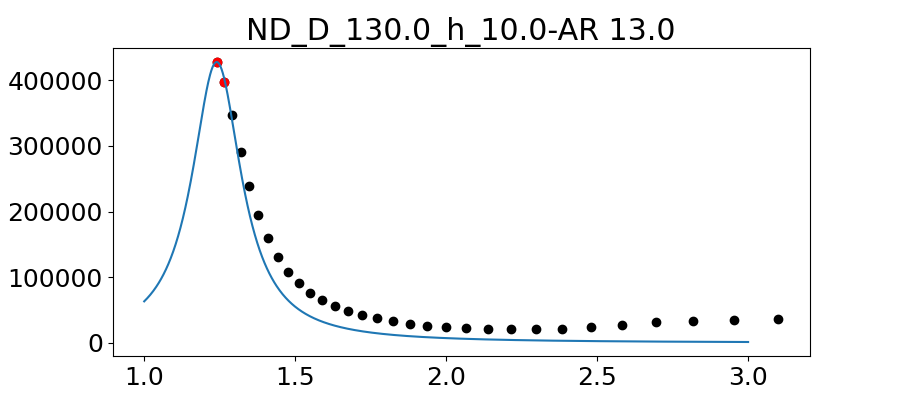

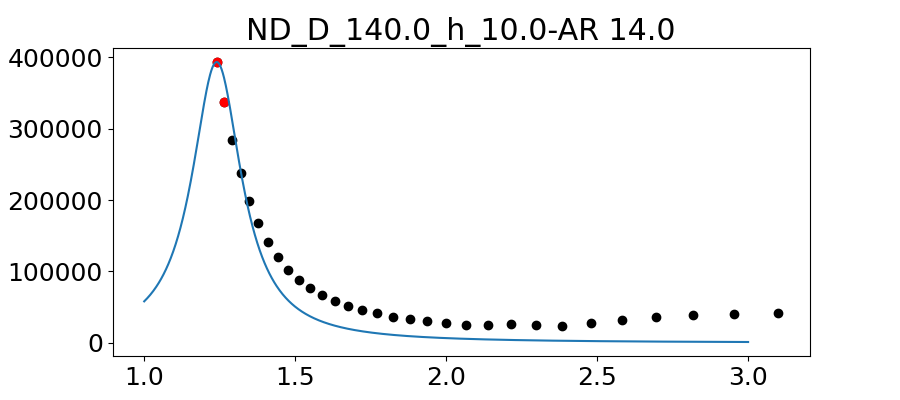

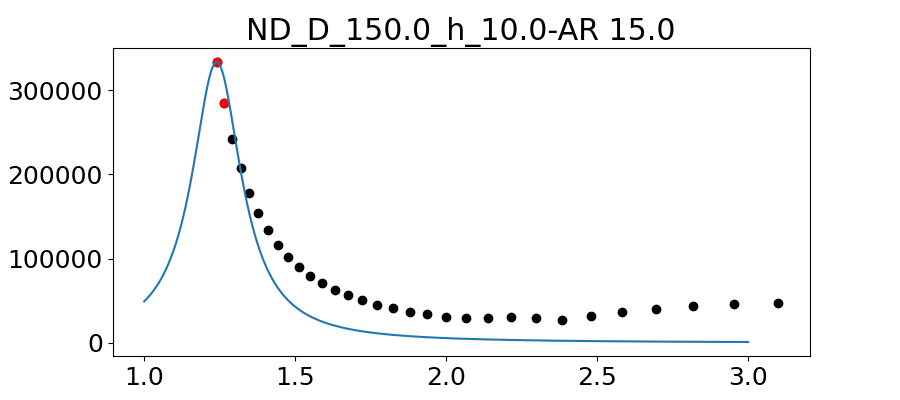

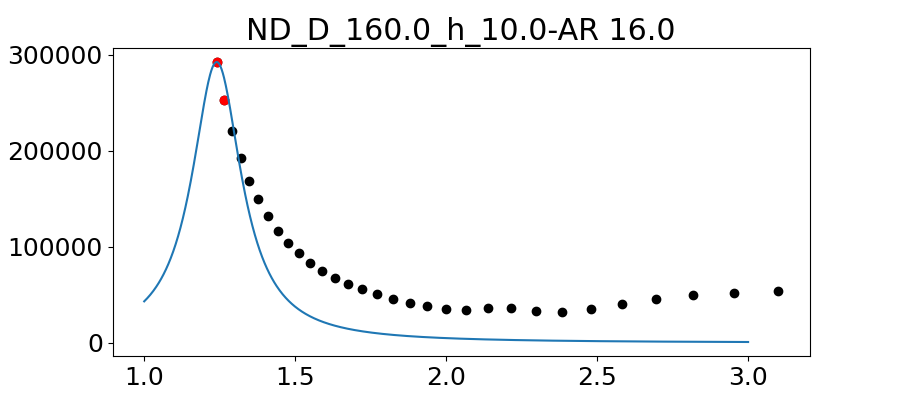

In [ ]:
E = np.linspace(1, 3, 1000)

if 1 :
        
    for key in Spectra_data :
        spectra = Spectra_data[key]

        if spectra['res_fit']['converged'] == 0 :
                
            fig, ax = plt.subplots(figsize = (9,4))

            ax.scatter(spectra['E'], spectra['Sigma_ext'], color='black')
            
            ax.plot(E, Lorentz_no_offset(E, *spectra['res_fit']['coeffs']))
            ax.set_title(key + '-' + 'AR '+ str(spectra['AR']))
            ax.scatter(spectra['E'][spectra['res_fit']['idx']], spectra['Sigma_ext'][spectra['res_fit']['idx']], color='red')

C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\AR_interpolations_plotting.py:30: RuntimeWarning: divide by zero encountered in divide
  cs = ax.contour(H, D, DD/HH, levels=[ 2.3], colors='black', alpha=0.6)
C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\AR_interpolations_plotting.py:30: RuntimeWarning: invalid value encountered in divide
  cs = ax.contour(H, D, DD/HH, levels=[ 2.3], colors='black', alpha=0.6)


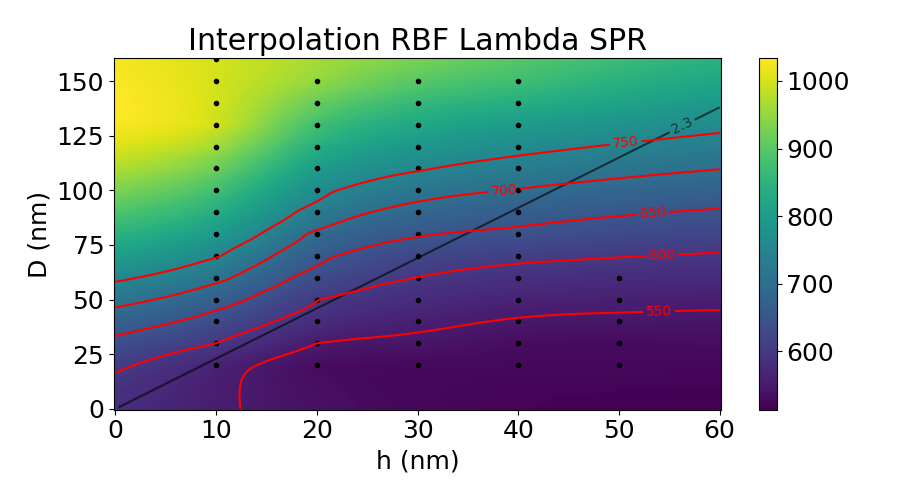

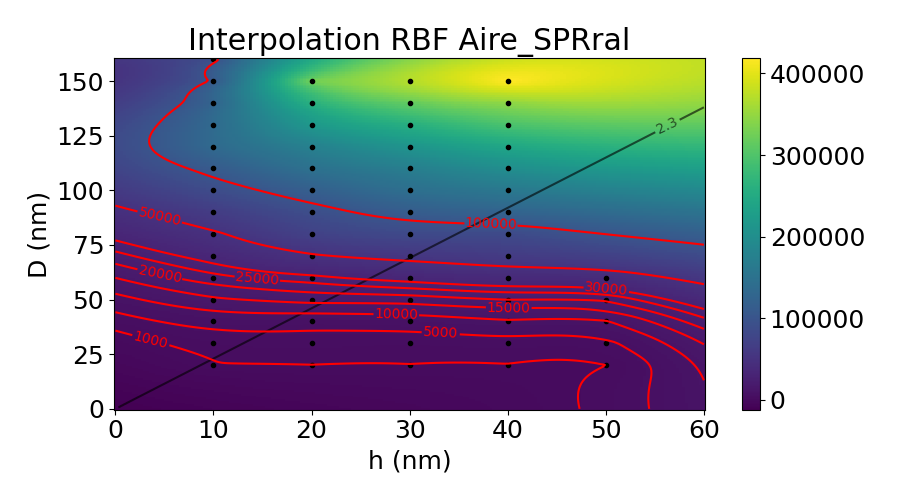

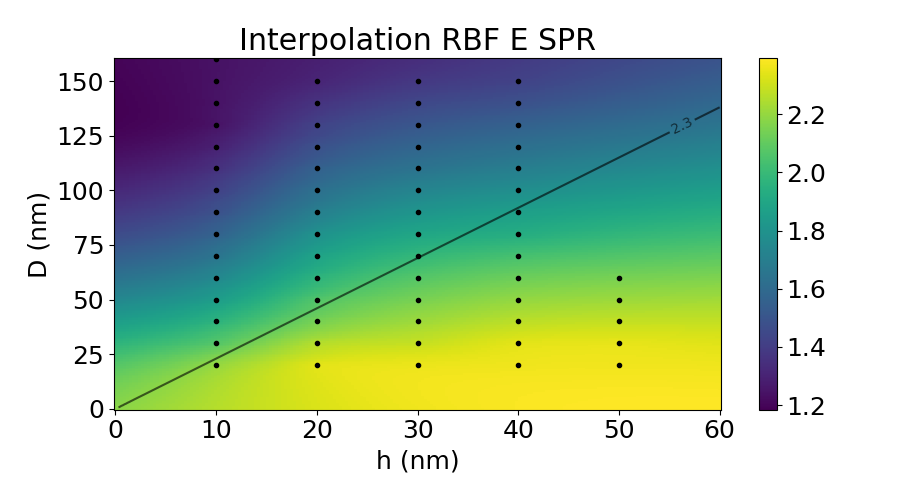

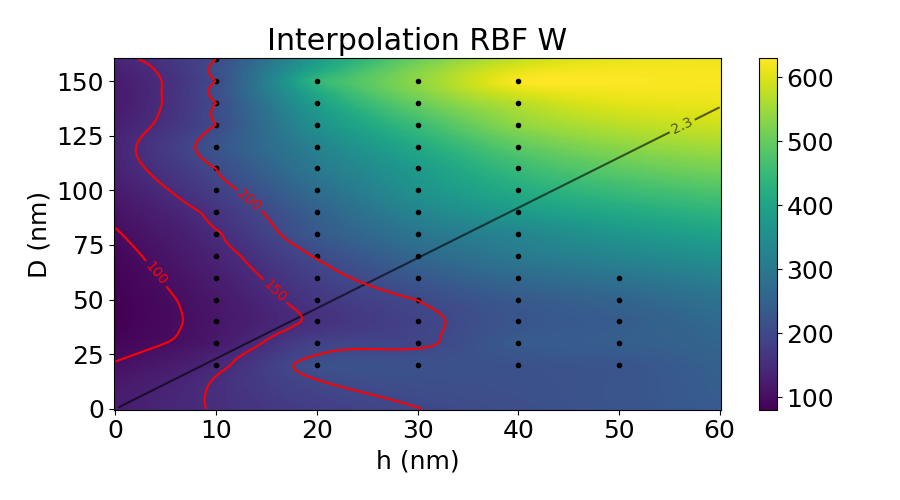

In [ ]:
Simu_data, Lda_RBF, E_RBF, W_RBF, Aire_RBF = get_simu_data_and_interpolate(dir_to_save, fname + '.csv', kernel='linear')


H_lisse = np.linspace(0, 60, 200)
D_lisse = np.linspace(0, 160, 200)
HH_lisse, DD_lisse = np.meshgrid( H_lisse, D_lisse)
points_lisses = np.array(list(zip(HH_lisse.flatten(), DD_lisse.flatten())))

plot_func_interp(Lda_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, Simu_data['points'], title='Lambda SPR', contour_specif=[550, 600, 650, 700, 750])
plot_func_interp(Aire_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, Simu_data['points'], title='Aire_SPRral', contour_specif=[1000, 5000, 10000, 15000, 20000, 25000, 30000, 50000, 100000])
plot_func_interp(E_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, Simu_data['points'], title='E SPR')
plot_func_interp(W_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, Simu_data['points'], title='W', contour_specif=[50, 100, 150, 200])

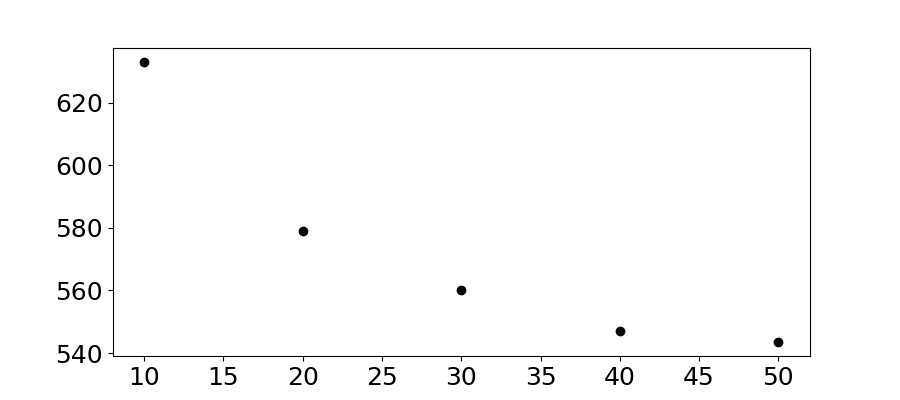

In [ ]:

fig, ax = plt.subplots(figsize = (9,4))


for key in Spectra_data :
    spectra = Spectra_data[key]
    
    if spectra['D'] == 40. :
        ax.scatter(spectra['h'], spectra['res_fit']['Lda_c'], color='black')
